# Stage 3, the visual companion: what equivariance *looks like*

`e3nn-equivariance.ipynb` checks equivariance with numbers (`3e-15 PASS`, `5e-01 FAIL`). This notebook goes over the same ground with pictures. Every section points back to the numerical section it illustrates.

**One sentence to keep in mind throughout:**
> An e3nn feature is not a list of numbers. It is a small **geometric object** attached to an atom (a number, an arrow, or a lobed shape), and the network must make those objects **turn with the molecule**.

The networks here are **untrained** (random weights). So the arrows point in arbitrary directions, and that is fine. What matters is not *where* they point, but *how they move* when the molecule moves.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="CUDA initialization")
import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.lines import Line2D
from IPython.display import HTML
from e3nn import o3
from e3nn import nn as enn
from e3nn.math import soft_one_hot_linspace

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)

# ---- the model from e3nn-equivariance.ipynb, sections 5-8 (same code, condensed) ----
def sio4(jitter=0.1):
    d = 1.61 / 3**0.5
    o = d * torch.tensor([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]], dtype=torch.get_default_dtype())
    pos = torch.cat([torch.zeros(1, 3), o])
    return pos + jitter * torch.randn_like(pos)

def radius_graph(pos, r_max):
    dist = torch.cdist(pos, pos)
    mask = (dist < r_max) & ~torch.eye(len(pos), dtype=torch.bool)
    src, dst = mask.nonzero().T
    return src, dst

r_max, lmax, num_basis = 3.0, 2, 8
irreps_sh = o3.Irreps.spherical_harmonics(lmax)

def radial_embedding(edge_vec):
    r = edge_vec.norm(dim=1)
    return soft_one_hot_linspace(r, start=0.0, end=r_max, number=num_basis,
                                 basis="smooth_finite", cutoff=True).mul(num_basis**0.5)

class Conv(torch.nn.Module):
    def __init__(self, irreps_in, irreps_out, num_basis=8, hidden=16, avg_num_neighbors=4.0):
        super().__init__()
        self.irreps_in, self.irreps_out = o3.Irreps(irreps_in), o3.Irreps(irreps_out)
        self.tp = o3.FullyConnectedTensorProduct(self.irreps_in, irreps_sh, self.irreps_out, shared_weights=False)
        self.fc = enn.FullyConnectedNet([num_basis, hidden, self.tp.weight_numel], torch.relu)
        self.avg_num_neighbors = avg_num_neighbors

    def forward(self, pos, x, src, dst):
        vec = pos[dst] - pos[src]
        sh = o3.spherical_harmonics(irreps_sh, vec, normalize=True, normalization="component")
        msg = self.tp(x[src], sh, self.fc(radial_embedding(vec)))
        out = torch.zeros(len(pos), self.irreps_out.dim, dtype=msg.dtype).index_add(0, dst, msg)
        return out / self.avg_num_neighbors**0.5

class Block(torch.nn.Module):
    def __init__(self, irreps_in, scalars="8x0e", gated="4x1o + 2x2e", act="gate"):
        super().__init__()
        gated = o3.Irreps(gated)
        self.gate = enn.Gate(scalars, [torch.nn.functional.silu],
                             f"{gated.num_irreps}x0e", [torch.sigmoid], gated)
        self.act = act
        self.irreps_out = self.gate.irreps_out
        pre = self.gate.irreps_in if act == "gate" else self.irreps_out
        self.conv = Conv(irreps_in, pre)
        self.self_int = o3.Linear(irreps_in, pre)

    def forward(self, pos, x, src, dst):
        h = self.conv(pos, x, src, dst) + self.self_int(x)
        return self.gate(h) if self.act == "gate" else torch.relu(h)

class TinyNet(torch.nn.Module):
    def __init__(self, act="gate", irreps_in="2x0e"):
        super().__init__()
        self.b1 = Block(irreps_in, act=act)
        self.b2 = Block(self.b1.irreps_out, act=act)
        self.irreps_out = self.b2.irreps_out

    def forward(self, pos, x):
        src, dst = radius_graph(pos, r_max)
        return self.b2(pos, self.b1(pos, x, src, dst), src, dst)

def D_of(irreps, R):   # accurate Wigner-D (section 12 workaround)
    return irreps.D_from_matrix(torch.stack([R, torch.eye(3, dtype=R.dtype)]))[0]

pos = sio4()
species = torch.tensor([0, 1, 1, 1, 1])
x_nodes = torch.nn.functional.one_hot(species, 2).to(torch.get_default_dtype())
net, net_relu = TinyNet(), TinyNet(act="relu")

V = slice(8, 11)                       # the first 1o channel of the output 8x0e + 4x1o + 2x2e
def vec_out(model, p):                 # "one arrow per atom"
    return model(p, x_nodes)[:, V]
print("model ready:", net.irreps_out)

model ready: 8x0e+4x1o+2x2e


In [2]:
# ---- drawing helpers ----
GOOD, CRITICAL, INK, MUTED, BAND, BG = "#0ca30c", "#d03b3b", "#0b0b0b", "#52514e", "#f0efec", "#fcfcfb"
BLUE, ORANGE, PURPLE = "#2a6fdb", "#e08a1e", "#7b4fc9"
POS_LOBE, NEG_LOBE = np.array(matplotlib.colors.to_rgba("#e4572e")), np.array(matplotlib.colors.to_rgba("#2a6fdb"))
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
                     "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9,
                     "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 100})

def np_(t):
    return t.detach().cpu().numpy()

def style3d(ax, title="", lim=1.5, center=(0, 0, 0), elev=18, azim=-60):
    c = center
    ax.set_xlim(c[0] - lim, c[0] + lim); ax.set_ylim(c[1] - lim, c[1] + lim); ax.set_zlim(c[2] - lim, c[2] + lim)
    ax.set_box_aspect((1, 1, 1)); ax.view_init(elev, azim)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.fill = False; a.pane.set_edgecolor(BAND)
    ax.set_title(title, loc="left", fontsize=9.5)
    return ax

def ax3d(fig, *spec, **kw):
    return style3d(fig.add_subplot(*spec, projection="3d"), **kw)

def draw_molecule(ax, p, bonds=None, alpha=1.0):
    p = np_(p)
    bonds = [(0, j) for j in range(1, len(p))] if bonds is None else bonds   # default: Si (atom 0) bonded to every O
    for i, j in bonds:
        ax.plot(*zip(p[i], p[j]), color=MUTED, lw=1.5, alpha=0.5 * alpha)
    ax.scatter(*p[:1].T, s=220, color="#4b5563", alpha=alpha, depthshade=False)
    ax.scatter(*p[1:].T, s=110, color="#9aa5b1", alpha=alpha, depthshade=False)

def draw_arrows(ax, p, v, color, scale=1.0, lw=2.0, alpha=1.0):
    scale = float(scale.detach()) if torch.is_tensor(scale) else float(scale)
    p, v = np_(p), np_(v) * scale
    ax.quiver(*p.T, *v.T, color=color, lw=lw, alpha=alpha, arrow_length_ratio=0.25)

def compare_legend(fig, actual_color, actual_label, expected_label):
    fig.legend(handles=[Line2D([], [], color=MUTED, lw=7, alpha=0.3, label=expected_label),
                        Line2D([], [], color=actual_color, lw=2, label=actual_label)],
               loc="lower center", ncol=2, frameon=False, fontsize=9)

## 1. A feature is a shape on a sphere (numerical sections 1–2)

A type-l feature has 2l+1 numbers. Think of them as coefficients that mix the 2l+1 spherical harmonics **Y_l** into one function on the sphere:

    f(u) = Σ_m c_m · Y_lm(u)        (u = a direction)

Draw that function with **radius = |f(u)|** and **colour = sign** (orange +, blue −) and you get a little shape. Here are all the basis shapes up to l = 2:
- **l = 0** is a ball. It looks the same from every direction, which is why scalars are invariant.
- **l = 1** is a dumbbell, i.e. an arrow. Its 3 coefficients are just (x, y, z).
- **l = 2** is a cloverleaf or a dumbbell-with-a-ring. It describes things like "stretched along one axis", the shape of a stress tensor or a quadrupole.

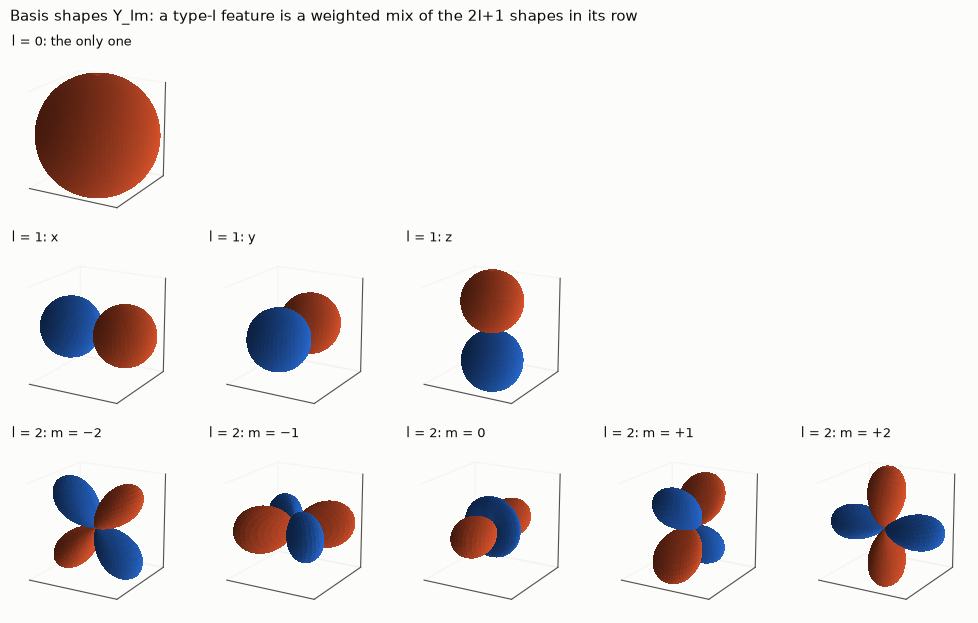

In [3]:
def sphere_points(n=48):
    th, ph = torch.linspace(0, torch.pi, n), torch.linspace(0, 2 * torch.pi, 2 * n)
    T, P = torch.meshgrid(th, ph, indexing="ij")
    return torch.stack([T.sin() * P.cos(), T.sin() * P.sin(), T.cos()], -1)

U = sphere_points()

def shape_of(coeffs, l):
    # a type-l feature (2l+1 numbers) as a function on the sphere: f(u) = sum_m c_m Y_lm(u)
    Y = o3.spherical_harmonics(l, U.reshape(-1, 3), normalize=True, normalization="component")
    return (Y @ coeffs).reshape(U.shape[:2])

def draw_glyph(ax, f, R=None, center=(0, 0, 0), size=1.0):
    # radius = |f(u)|, colour = sign; optionally rotate the drawn surface by R
    xyz = U * (f.abs() / f.abs().max() * size)[..., None]
    if R is not None:
        xyz = xyz @ R.T
    xyz = xyz + torch.tensor(center)
    col = np.where(np_(f)[..., None] > 0, POS_LOBE, NEG_LOBE)
    ax.plot_surface(*np_(xyz).transpose(2, 0, 1), facecolors=col, linewidth=0,
                    antialiased=False, shade=True, rcount=U.shape[0], ccount=U.shape[1])

names = {0: ["the only one"], 1: ["x", "y", "z"], 2: ["m = −2", "m = −1", "m = 0", "m = +1", "m = +2"]}
fig = plt.figure(figsize=(10, 6.3))
for l in range(3):
    for m in range(2 * l + 1):
        ax = ax3d(fig, 3, 5, 5 * l + m + 1, title=f"l = {l}: {names[l][m]}", lim=0.8)
        draw_glyph(ax, shape_of(torch.eye(2 * l + 1)[m], l))
fig.suptitle("Basis shapes Y_lm: a type-l feature is a weighted mix of the 2l+1 shapes in its row",
             x=0.02, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

### Rotating the numbers = rotating the shape

This is what the Wigner-D matrix *means*. Take a random `2e` feature (5 numbers c) and draw its shape (a). Now there are two ways to get a rotated version:
- **(b)** grab the drawn shape and physically turn it by R
- **(c)** multiply the 5 numbers by the 5×5 matrix D(R), and draw the shape of the result

(b) and (c) are the **same picture**. That is the whole content of `Y(Rr) = D(R) Y(r)` from numerical section 5. D is simply "how the 5 numbers must change so that the shape turns rigidly".

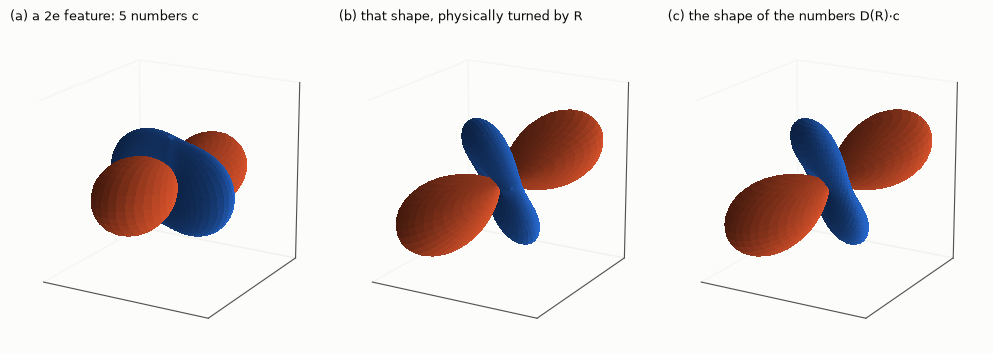

c      = [ 0.12  0.21  2.1  -0.22  0.25]
D(R)·c = [ 0.82  1.33  0.77  1.16 -0.46]   <- different numbers, same shape turned


In [4]:
c = torch.randn(5)
R = o3.angles_to_matrix(torch.tensor(0.9), torch.tensor(0.8), torch.tensor(0.3))
Dc = D_of(o3.Irreps("2e"), R) @ c

fig = plt.figure(figsize=(10, 3.6))
draw_glyph(ax3d(fig, 1, 3, 1, title="(a) a 2e feature: 5 numbers c", lim=0.8), shape_of(c, 2))
draw_glyph(ax3d(fig, 1, 3, 2, title="(b) that shape, physically turned by R", lim=0.8), shape_of(c, 2), R=R)
draw_glyph(ax3d(fig, 1, 3, 3, title="(c) the shape of the numbers D(R)·c", lim=0.8), shape_of(Dc, 2))
plt.tight_layout(); plt.show()
print("c      =", np.round(np_(c), 2))
print("D(R)·c =", np.round(np_(Dc), 2), "  <- different numbers, same shape turned")

## 2. D never mixes different l (numerical sections 2–3)

Below is the actual D matrix for a feature `2x0e + 2x1o + 1x2e`, drawn as an image (white = 0). Each square on the diagonal is one irrep:
- **Left, rotation:** the 0e blocks are exactly 1, so scalars never change. Each 1o block is the 3×3 rotation matrix R, and the 2e block is a dense 5×5. Everything off the diagonal blocks is zero, so a rotation never turns a scalar into part of a vector.
- **Right, inversion −I:** every block becomes ±identity. The `1o` blocks get **−1** (arrows flip) and the `0e` and `2e` blocks get **+1**. A `1e` block would also get +1, and that one sign is the *only* difference between `1o` and `1e` (numerical section 3).

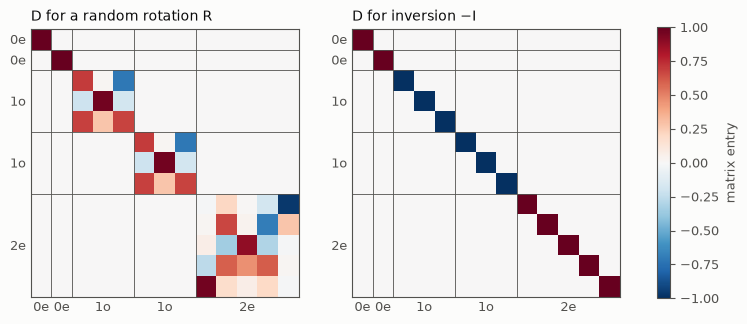

In [5]:
ir = o3.Irreps("2x0e + 2x1o + 1x2e")
blocks = [(str(i.ir), i.ir.dim) for i in ir for _ in range(i.mul)]
edges = np.cumsum([0] + [d for _, d in blocks]) - 0.5

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.4))
for ax, (g, name) in zip(axes, [(o3.rand_matrix(), "D for a random rotation R"),
                                (-torch.eye(3), "D for inversion −I")]):
    im = ax.imshow(np_(D_of(ir, g)), cmap="RdBu_r", vmin=-1, vmax=1)
    for e in edges:
        ax.axhline(e, color=MUTED, lw=0.6); ax.axvline(e, color=MUTED, lw=0.6)
    centers = (edges[:-1] + edges[1:]) / 2
    ax.set_xticks(centers, [b for b, _ in blocks]); ax.set_yticks(centers, [b for b, _ in blocks])
    ax.tick_params(length=0); ax.set_title(name)
fig.colorbar(im, ax=axes, shrink=0.8, label="matrix entry")
plt.show()

## 3. The tensor product, as geometry (numerical sections 3–4)

`1o ⊗ 1o → 0e + 1e + 2e` takes two arrows and returns three objects:
- **0e:** a·b, one number (how aligned a and b are). Drawn as a ball whose colour is its sign.
- **1e:** a×b, an arrow perpendicular to both.
- **2e:** the traceless part of a bᵀ, a cloverleaf lying in the a–b plane that encodes "stretched along these directions".

Every tensor product in the network is a version of this: combine a neighbour's shape with the edge-direction shape, and get new shapes out.

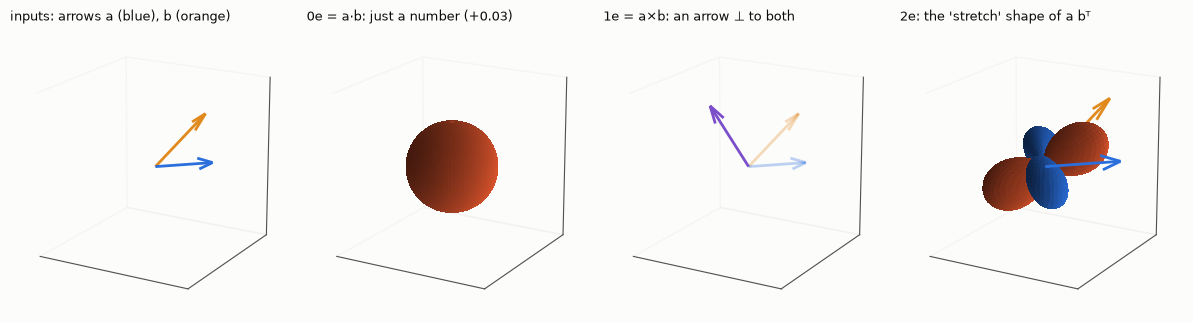

In [6]:
a, b = torch.tensor([1.0, -0.3, 0.3]), torch.tensor([0.2, 1.0, 0.5])
tp = o3.FullTensorProduct("1o", "1o")
s0, s1, s2 = [tp(a, b)[sl] for sl in tp.irreps_out.slices()]
O = torch.zeros(1, 3)

fig = plt.figure(figsize=(12, 3.5))
ax = ax3d(fig, 1, 4, 1, title="inputs: arrows a (blue), b (orange)", lim=1.1)
draw_arrows(ax, O, a[None], BLUE); draw_arrows(ax, O, b[None], ORANGE)
ax = ax3d(fig, 1, 4, 2, title=f"0e = a·b: just a number ({s0.item():+.2f})", lim=1.1)
draw_glyph(ax, shape_of(s0, 0), size=0.6)
ax = ax3d(fig, 1, 4, 3, title="1e = a×b: an arrow ⊥ to both", lim=1.1)
draw_arrows(ax, O, a[None], BLUE, alpha=0.3); draw_arrows(ax, O, b[None], ORANGE, alpha=0.3)
draw_arrows(ax, O, s1[None], PURPLE, scale=1 / s1.norm())
ax = ax3d(fig, 1, 4, 4, title="2e: the 'stretch' shape of a bᵀ", lim=1.1)
draw_glyph(ax, shape_of(s2, 2), size=0.9)
draw_arrows(ax, O, a[None], BLUE, scale=1.3); draw_arrows(ax, O, b[None], ORANGE, scale=1.3)
plt.tight_layout(); plt.show()

### Why a×b is a *pseudo*vector: hold it up to a mirror

Reflect a and b in the mirror z → −z (grey plane). Then compare:
- **Grey:** where a true arrow `1o` would end up, i.e. the mirror image of a×b.
- **Purple:** what you actually get by recomputing the cross product from the mirrored inputs.

They point in **opposite** directions. A cross product encodes a sense of *rotation* (think of a spinning wheel), and a mirror reverses rotation. That is the extra sign in the `1e` block from section 2, and it is why the rotation-only test cannot see a `1o`/`1e` mix-up: the two only disagree in a mirror.

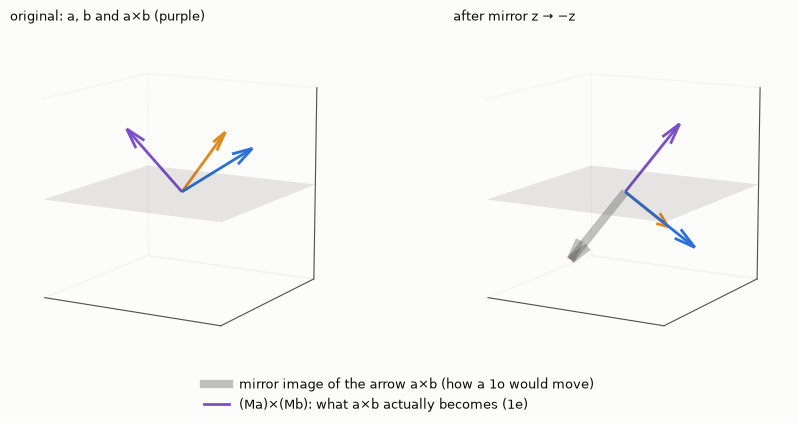

In [7]:
M = torch.diag(torch.tensor([1.0, 1.0, -1.0]))
a, b = torch.tensor([0.9, 0.1, 0.6]), torch.tensor([0.1, 0.9, 0.6])
axb, Ma, Mb = torch.linalg.cross(a, b), a @ M.T, b @ M.T

def mirror_plane(ax):
    X, Y = np.meshgrid([-1.2, 1.2], [-1.2, 1.2])
    ax.plot_surface(X, Y, 0 * X, color=MUTED, alpha=0.12, linewidth=0)

fig = plt.figure(figsize=(9, 4.2))
ax = ax3d(fig, 1, 2, 1, title="original: a, b and a×b (purple)", lim=1.2, elev=12)
mirror_plane(ax)
draw_arrows(ax, O, a[None], BLUE); draw_arrows(ax, O, b[None], ORANGE); draw_arrows(ax, O, axb[None], PURPLE)
ax = ax3d(fig, 1, 2, 2, title="after mirror z → −z", lim=1.2, elev=12)
mirror_plane(ax)
draw_arrows(ax, O, Ma[None], BLUE); draw_arrows(ax, O, Mb[None], ORANGE)
draw_arrows(ax, O, (axb @ M.T)[None], MUTED, lw=6, alpha=0.35)
draw_arrows(ax, O, torch.linalg.cross(Ma, Mb)[None], PURPLE)
fig.legend(handles=[Line2D([], [], color=MUTED, lw=6, alpha=0.35, label="mirror image of the arrow a×b (how a 1o would move)"),
                    Line2D([], [], color=PURPLE, lw=2, label="(Ma)×(Mb): what a×b actually becomes (1e)")],
           loc="lower center", ncol=1, frameon=False)
plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()

## 4. The radial part sees only distance (numerical section 6)

Each edge's *direction* goes into the spherical harmonics (the shapes above). Its *length* goes through these 8 smooth bumps, and then an MLP turns them into the tensor-product weights. Rotating the molecule leaves every distance (the ticks at the bottom) unchanged, so the weights are unchanged. That is why the MLP is allowed to be an ordinary ReLU network.

Every bump reaches **0 at r_max**, so an atom drifting across the cutoff fades out smoothly instead of popping in or out.

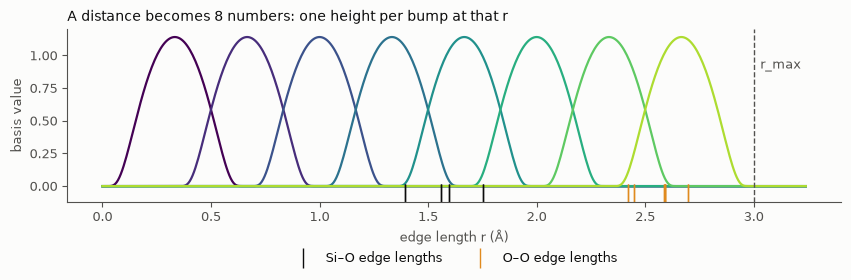

In [8]:
r = torch.linspace(0, r_max * 1.08, 500)
B = soft_one_hot_linspace(r, 0.0, r_max, num_basis, basis="smooth_finite", cutoff=True)
src, dst = radius_graph(pos, r_max)
d = (pos[dst] - pos[src]).norm(dim=1)
sio = (src == 0) | (dst == 0)

fig, ax = plt.subplots(figsize=(8.5, 3))
cmap = plt.get_cmap("viridis")
for k in range(num_basis):
    ax.plot(np_(r), np_(B[:, k]), color=cmap(k / num_basis), lw=1.6)
ax.plot(np_(d[sio]), np.full(int(sio.sum()), -0.06), "|", color=INK, ms=14, label="Si–O edge lengths")
ax.plot(np_(d[~sio]), np.full(int((~sio).sum()), -0.06), "|", color=ORANGE, ms=14, label="O–O edge lengths")
ax.axvline(r_max, color=MUTED, ls="--", lw=1); ax.text(r_max * 1.01, 0.9, "r_max", color=MUTED)
ax.set_xlabel("edge length r (Å)"); ax.set_ylabel("basis value"); ax.set_ylim(-0.12, None)
ax.set_title("A distance becomes 8 numbers: one height per bump at that r")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 5. The central picture: the arrows ride along with the molecule (numerical sections 7–9)

The `max err 3e-15` / `5e-01` numbers measure exactly this. Panel (a) shows TinyNet's first `1o` output: one arrow per atom. Then we rotate the molecule by R and compare two things:
- **grey halo**, "run then rotate": take the original arrows and turn them with the molecule. This is what equivariance says we *should* get.
- **coloured**, "rotate then run": feed the rotated molecule into the network and draw what comes out.

For the gate net (b) the coloured arrow sits exactly inside the halo. For the ReLU net (c) they disagree. The ReLU net's *idea* of which way to point depends on how the molecule happens to sit relative to the x, y, z axes.

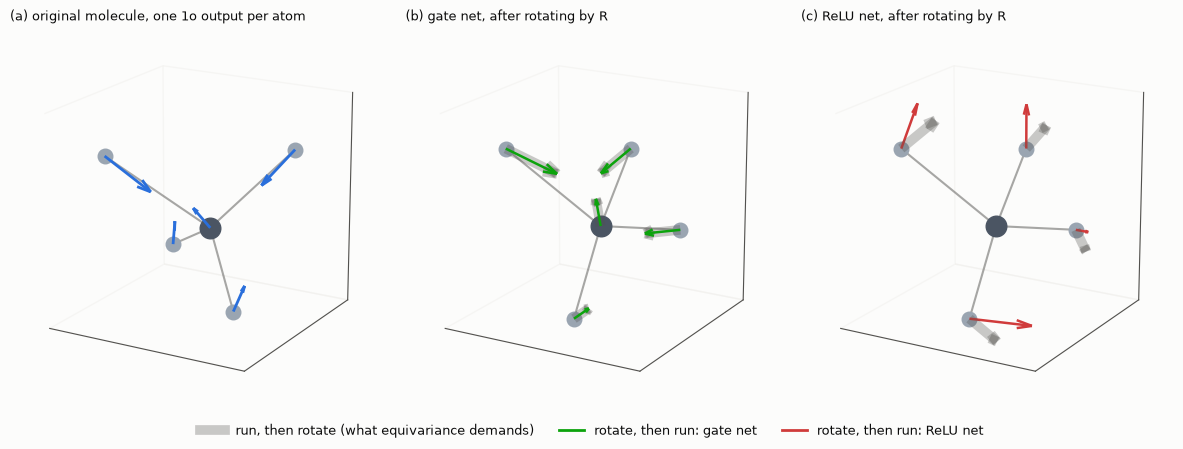

In [9]:
R = o3.angles_to_matrix(torch.tensor(1.1), torch.tensor(0.9), torch.tensor(-0.4))
pr = pos @ R.T

fig = plt.figure(figsize=(12, 4.3))
ax = ax3d(fig, 1, 3, 1, title="(a) original molecule, one 1o output per atom")
draw_molecule(ax, pos); v = vec_out(net, pos); draw_arrows(ax, pos, v, BLUE, 0.9 / v.norm(dim=1).max())
for k, (model, name, col) in enumerate([(net, "(b) gate net, after rotating by R", GOOD),
                                        (net_relu, "(c) ReLU net, after rotating by R", CRITICAL)]):
    ax = ax3d(fig, 1, 3, k + 2, title=name)
    draw_molecule(ax, pr)
    expected = vec_out(model, pos) @ R.T          # run, then rotate the output
    actual = vec_out(model, pr)                   # rotate the input, then run
    s = 0.9 / torch.cat([expected, actual]).norm(dim=1).max()
    draw_arrows(ax, pr, expected, MUTED, s, lw=7, alpha=0.3)
    draw_arrows(ax, pr, actual, col, s, lw=1.8)
fig.legend(handles=[Line2D([], [], color=MUTED, lw=7, alpha=0.3, label="run, then rotate (what equivariance demands)"),
                    Line2D([], [], color=GOOD, lw=2, label="rotate, then run: gate net"),
                    Line2D([], [], color=CRITICAL, lw=2, label="rotate, then run: ReLU net")],
           loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

### The same test, 40 rotations at once

Present the molecule to the network in 40 random orientations. Each time, take the output arrows and **turn them back** into the original frame, then draw all 40 on top of each other.
- **Equivariant:** all 40 land on the same arrow, so you see one sharp arrow per atom. The network "sees" the same molecule no matter how it is held.
- **ReLU:** a fan of arrows. The answer depends on the orientation, which a physical property never does.

This is what the "100 random O(3) elements" test in numerical section 12 is doing behind the scenes.

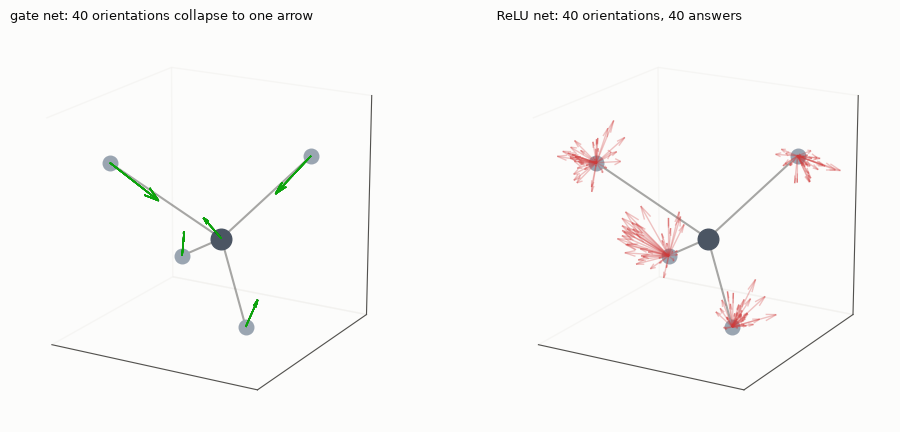

In [10]:
Rs = o3.rand_matrix(40)
fig = plt.figure(figsize=(10, 4.4))
for k, (model, name, col) in enumerate([(net, "gate net: 40 orientations collapse to one arrow", GOOD),
                                        (net_relu, "ReLU net: 40 orientations, 40 answers", CRITICAL)]):
    ax = ax3d(fig, 1, 2, k + 1, title=name)
    draw_molecule(ax, pos)
    vs = torch.stack([vec_out(model, pos @ Rk.T) @ Rk for Rk in Rs])   # @ Rk undoes the rotation (row vectors)
    s = 0.9 / vs.norm(dim=-1).max()
    for v in vs:
        draw_arrows(ax, pos, v, col, s, lw=1.0, alpha=0.3)
plt.tight_layout(); plt.show()

### Watch it move

The molecule spins about a tilted axis. At **every** frame the arrows are recomputed by running the network on the rotated input; nothing is rotated after the fact. Left: the arrows are fixed to the molecule like sticks glued to it. Right: they slide and flicker relative to the molecule. Press play.

In [11]:
axis = torch.tensor([1.0, 1.0, 0.5]); axis = axis / axis.norm()
frames = 36
data = []
for k in range(frames):
    Rk = o3.axis_angle_to_matrix(axis, torch.tensor(2 * torch.pi * k / frames))
    p = pos @ Rk.T
    data.append((p, vec_out(net, p).detach(), vec_out(net_relu, p).detach()))
s_gate = 0.9 / max(d[1].norm(dim=1).max() for d in data)
s_relu = 0.9 / max(d[2].norm(dim=1).max() for d in data)

fig = plt.figure(figsize=(8, 4), dpi=72)
axs = [fig.add_subplot(1, 2, k + 1, projection="3d") for k in range(2)]

def draw_frame(k):
    p, vg, vr = data[k]
    for ax, v, s, col, name in [(axs[0], vg, s_gate, GOOD, "gate net"), (axs[1], vr, s_relu, CRITICAL, "ReLU net")]:
        ax.cla(); style3d(ax, title=name)
        draw_molecule(ax, p); draw_arrows(ax, p, v, col, s, lw=2.2)

anim = animation.FuncAnimation(fig, draw_frame, frames=frames, interval=150)
plt.close(fig)
HTML(anim.to_jshtml())

## 6. Why ReLU breaks it and the gate does not (numerical sections 8–9)

Feed in 24 arrows of equal length, one per direction around a circle (colour = direction).
- **ReLU** zeroes the negative x and negative y components. Arrows snap onto the axes, and the third quadrant vanishes entirely. The result depends on *where the axes are*, which the physics has no notion of.
- **Gate** multiplies each whole arrow by σ(scalar). The scalar is invariant, so every direction is treated identically: the circle just shrinks.
- **Right panel:** the hand example from numerical section 9, v = (1, −1) with a 90° turn. Doing "rotate then ReLU" and "ReLU then rotate" gives two different arrows.

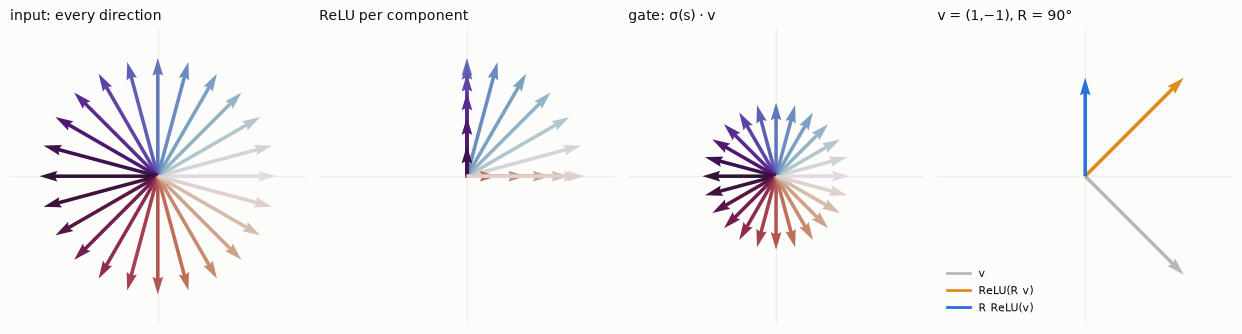

In [12]:
theta = torch.linspace(0, 2 * torch.pi, 25)[:-1]
v = torch.stack([theta.cos(), theta.sin()], 1)
colors = plt.cm.twilight(np_(theta) / (2 * np.pi))

def panel2d(ax, title, lim=1.25):
    ax.axhline(0, color=BAND, lw=1, zorder=0); ax.axvline(0, color=BAND, lw=1, zorder=0)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)
    for s in ax.spines.values(): s.set_visible(False)

def arrows2d(ax, vecs, color, **kw):
    vecs = np_(vecs)
    ax.quiver(np.zeros(len(vecs)), np.zeros(len(vecs)), *vecs.T, color=color,
              angles="xy", scale_units="xy", scale=1, width=0.012, **kw)

fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.4))
panel2d(axes[0], "input: every direction"); arrows2d(axes[0], v, colors)
panel2d(axes[1], "ReLU per component"); arrows2d(axes[1], torch.relu(v), colors)
panel2d(axes[2], "gate: σ(s) · v"); arrows2d(axes[2], torch.sigmoid(torch.tensor(0.5)) * v, colors)

Rz = torch.tensor([[0.0, -1.0], [1.0, 0.0]])
v0 = torch.tensor([1.0, -1.0])
panel2d(axes[3], "v = (1,−1), R = 90°", lim=1.5)
arrows2d(axes[3], v0[None], MUTED, alpha=0.4)
arrows2d(axes[3], torch.relu(Rz @ v0)[None], ORANGE)
arrows2d(axes[3], (Rz @ torch.relu(v0))[None], BLUE)
axes[3].legend(handles=[Line2D([], [], color=MUTED, alpha=0.4, lw=2, label="v"),
                        Line2D([], [], color=ORANGE, lw=2, label="ReLU(R v)"),
                        Line2D([], [], color=BLUE, lw=2, label="R ReLU(v)")],
               frameon=False, loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

## 7. Why max aggregation breaks it and sum does not (numerical section 7)

Three messages (grey) arrive at a node. We aggregate them in two different coordinate frames, whose axes are drawn as thin lines.
- **Sum (green)** is tip-to-tail addition, a purely geometric operation. It is the same arrow in both frames.
- **Component-wise max (red)** takes the largest coordinate along each axis, so its answer depends on the axes. In the right frame it points somewhere else; the faint red arrow is the left frame's answer, for comparison.

Scalars (`0e`) have no axes, so max over them is fine. That is why the per-irrep breakdown showed `0e: 1e-15` but `1o: 1e+00`.

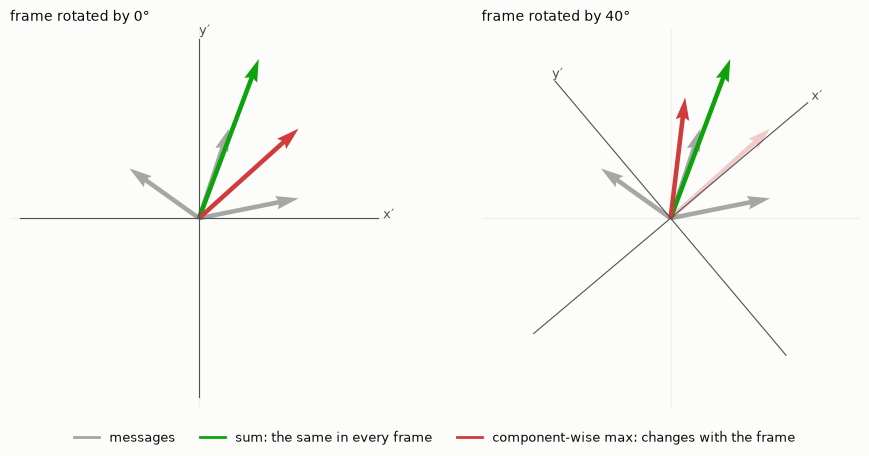

In [13]:
msgs = torch.tensor([[1.0, 0.2], [0.3, 0.9], [-0.7, 0.5]])
total = msgs.sum(0)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.5))
maxes = []
for ax, phi in zip(axes, [0.0, 0.7]):
    Q = torch.tensor([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])   # columns = this frame's axes
    mx = (msgs @ Q).max(0).values @ Q.T                                          # componentwise max in-frame, back to world
    maxes.append(mx)
    panel2d(ax, f"frame rotated by {np.degrees(phi):.0f}°", lim=1.9)
    for axis_vec, lab in zip(np_(Q.T), ["x′", "y′"]):
        ax.plot(*np.stack([-1.8 * axis_vec, 1.8 * axis_vec]).T, color=MUTED, lw=0.8)
        ax.text(*(1.85 * axis_vec), lab, color=MUTED)
    arrows2d(ax, msgs, MUTED, alpha=0.5)
    arrows2d(ax, total[None], GOOD)
    if len(maxes) == 2:
        arrows2d(ax, maxes[0][None], CRITICAL, alpha=0.25)
    arrows2d(ax, mx[None], CRITICAL)
fig.legend(handles=[Line2D([], [], color=MUTED, alpha=0.5, lw=2, label="messages"),
                    Line2D([], [], color=GOOD, lw=2, label="sum: the same in every frame"),
                    Line2D([], [], color=CRITICAL, lw=2, label="component-wise max: changes with the frame")],
           loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

## 8. Translation: a molecule has no special origin (numerical section 10)

Shift the molecule (the faint copy is the original). The arrows on the shifted copy should be **identical** to the original ones (grey halo).
- **TinyNet** uses only *differences* of positions, so the arrows stay the same.
- **`pos` fed in as a `1o` feature:** the network can see "where am I relative to the origin", so the arrows change. It still passes the rotation test, because rotating about the origin keeps every distance *to the origin* the same. That is why every symmetry needs its own test.

Notice the red arrows don't just turn, they *grow*: the network is reacting to "I am now farther from the origin", a quantity that has no physical meaning.

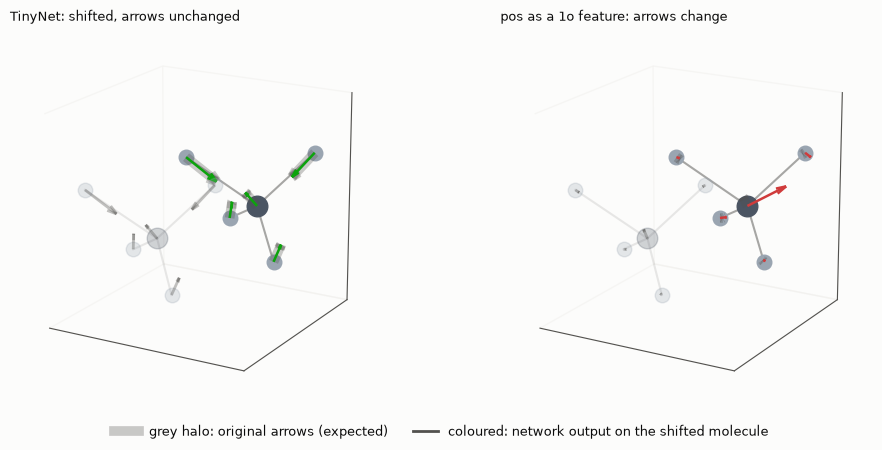

In [14]:
net_pos = TinyNet(irreps_in="2x0e + 1x1o")
f_pos = lambda p: net_pos(p, torch.cat([x_nodes, p], 1))[:, V]
t = torch.tensor([1.6, 1.2, 0.6])

fig = plt.figure(figsize=(10, 4.5))
for k, (f, name, col) in enumerate([(lambda p: vec_out(net, p), "TinyNet: shifted, arrows unchanged", GOOD),
                                    (f_pos, "pos as a 1o feature: arrows change", CRITICAL)]):
    ax = ax3d(fig, 1, 2, k + 1, title=name, lim=2.2, center=np_(t / 2))
    v0, v1 = f(pos), f(pos + t)
    s = 0.9 / torch.cat([v0, v1]).norm(dim=1).max()
    draw_molecule(ax, pos, alpha=0.25); draw_arrows(ax, pos, v0, MUTED, s, alpha=0.35)
    draw_molecule(ax, pos + t)
    draw_arrows(ax, pos + t, v0, MUTED, s, lw=7, alpha=0.3)
    draw_arrows(ax, pos + t, v1, col, s, lw=1.8)
compare_legend(fig, MUTED, "coloured: network output on the shifted molecule",
               "grey halo: original arrows (expected)")
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

## 9. Parity, seen on a flat molecule (numerical section 11)

Put all 5 atoms in the z = 0 plane. The mirror z → −z maps the molecule onto itself, so every output must look the same in the mirror:
- a true vector **`1o`** must lie **in the plane**. An arrow sticking up would flip to point down, which is not the same picture.
- a pseudovector **`1e`** must point **straight out of the plane**. As section 3 showed, an out-of-plane pseudovector is what survives the mirror, like the axis of a wheel spinning in the plane.

Forces on a flat molecule lie in the plane. So if forces were mislabelled `1e`, the network could only ever output perpendicular "forces", **whatever the weights**. This is a physical impossibility, not just a test failure. The two views show the same scene from above and edge-on.

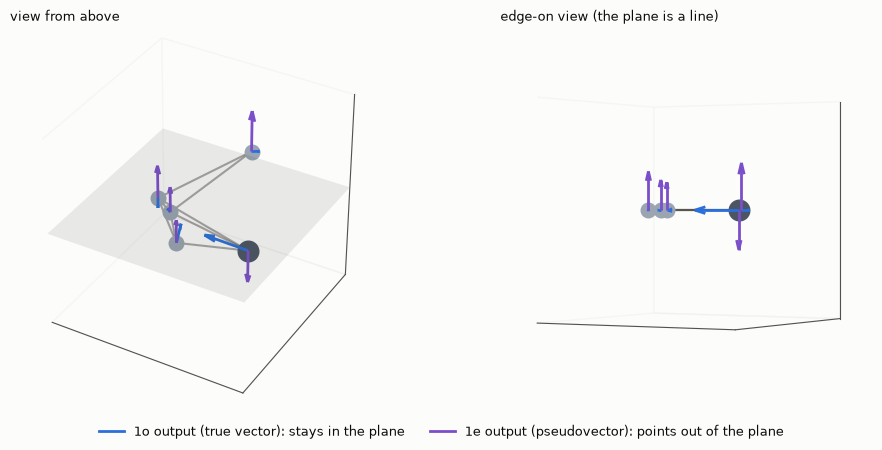

In [15]:
torch.manual_seed(1)
b1 = Block("2x0e", gated="4x1o + 4x1e + 2x2e")
b2 = Block(b1.irreps_out, gated="4x1o + 4x1e + 2x2e")
pos_planar = torch.cat([torch.randn(5, 2), torch.zeros(5, 1)], dim=1)
s, d = radius_graph(pos_planar, r_max)
h = b2(pos_planar, b1(pos_planar, x_nodes, s, d), s, d)
first = {}
for mi, sl in zip(b2.irreps_out, b2.irreps_out.slices()):
    first.setdefault(str(mi.ir), h[:, sl.start:sl.start + 3])
v1o, v1e = first["1o"], first["1e"]

c = np_(pos_planar.mean(0))
fig = plt.figure(figsize=(10, 4.5))
for k, (elev, title) in enumerate([(35, "view from above"), (0, "edge-on view (the plane is a line)")]):
    ax = ax3d(fig, 1, 2, k + 1, title=title, lim=2.0, center=c, elev=elev, azim=-60)
    X, Y = np.meshgrid([c[0] - 2, c[0] + 2], [c[1] - 2, c[1] + 2])
    ax.plot_surface(X, Y, 0 * X, color=MUTED, alpha=0.1, linewidth=0)
    draw_molecule(ax, pos_planar, bonds=[(i, j) for i, j in zip(s.tolist(), d.tolist()) if i < j])
    draw_arrows(ax, pos_planar, v1o, BLUE, 0.9 / v1o.norm(dim=1).max())
    draw_arrows(ax, pos_planar, v1e, PURPLE, 0.9 / v1e.norm(dim=1).max())
fig.legend(handles=[Line2D([], [], color=BLUE, lw=2, label="1o output (true vector): stays in the plane"),
                    Line2D([], [], color=PURPLE, lw=2, label="1e output (pseudovector): points out of the plane")],
           loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

## 10. Forces: downhill on an energy landscape (numerical section 13)

Pick two coordinates of the molecule, here *one coordinate of one atom* and *one coordinate of another*, and vary just those two. Every point in the plane below is a whole configuration, and the model's energy E over it is a landscape, drawn as contour lines. We chose the pair of coordinates where the direct head is *least* conservative, i.e. the largest entry of J − Jᵀ from numerical section 13.
- **(a) F = −∂E/∂x:** every arrow points straight **downhill**, perpendicular to the contours. Forces that come from a landscape are automatically `1o`, they sum to zero, and they are **conservative**.
- **(b) a direct `1o` head:** it is equivariant, but it knows nothing about any landscape. Its arrows are not the downhill of *any* E.
- **(c) the conservative test, as a walk:** go around the dashed loop 20 times, adding up the work F·dx. The faint wiggle inside each lap is just climbing and descending. The dots mark the end of each lap. With gradient forces every lap ends at **0**, back where you started. With the direct head every lap loses the same amount, so the dots fall in a straight line. (The green line's tiny slope, about 0.1% per lap, is the error of summing F·dx over 640 finite steps. The red slope is about 25× larger and does not shrink with more steps.) In an MD run that is **energy drift**, and it is what "Jacobian asymmetry 1e+00" meant.

most asymmetric pair: atom 0 x and atom 1 z   dF_a/dx_b = +0.08 vs dF_b/dx_a = -6.29


−∂E/∂x           net work per lap = -0.0011  (fraction of the work done along one lap)


direct 1o head   net work per lap = -0.0263  (fraction of the work done along one lap)


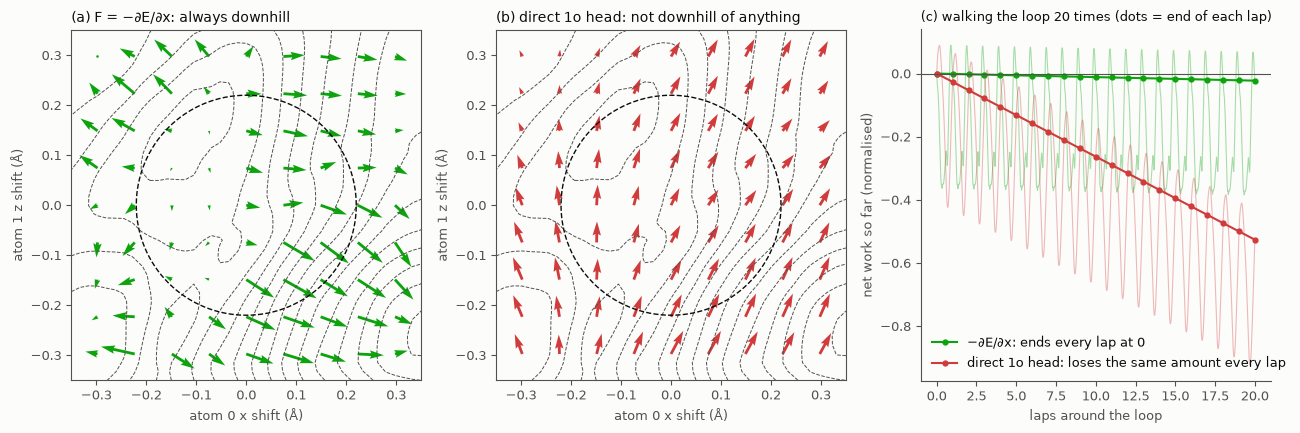

In [16]:
class EnergyModel(torch.nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone
        self.readout = o3.Linear(backbone.irreps_out, "0e")

    def forward(self, pos, x):
        return self.readout(self.backbone(pos, x)).sum()

emodel = EnergyModel(net)
direct_head = o3.Linear(net.irreps_out, "1x1o")

def F_grad(p):                                             # -dE/dx, flattened to (15,)
    p = p.detach().requires_grad_(True)
    (g,) = torch.autograd.grad(emodel(p, x_nodes), p)
    return -g.reshape(-1)

def F_direct(p):
    return direct_head(net(p, x_nodes)).reshape(-1)

# choose the two coordinates where the direct head is least conservative
J = torch.autograd.functional.jacobian(lambda q: F_direct(q.reshape(-1, 3)), pos.reshape(-1))
A = (J - J.T).abs().triu(1)
ia, ib = divmod(A.argmax().item(), A.shape[1])
xyz = "xyz"
name_a, name_b = f"atom {ia // 3} {xyz[ia % 3]}", f"atom {ib // 3} {xyz[ib % 3]}"
lab_a, lab_b = f"{name_a} shift (Å)", f"{name_b} shift (Å)"
print(f"most asymmetric pair: {name_a} and {name_b}   "
      f"dF_a/dx_b = {J[ia, ib].item():+.2f} vs dF_b/dx_a = {J[ib, ia].item():+.2f}")

def moved(u, w):
    q = pos.reshape(-1).clone(); q[ia] += u; q[ib] += w
    return q.reshape(-1, 3)

L = 0.35
g = torch.linspace(-L, L, 41)
with torch.no_grad():
    E = torch.tensor([[emodel(moved(u, w), x_nodes).item() for u in g] for w in g])

ga = torch.linspace(-0.85 * L, 0.85 * L, 9)
GU, GW = torch.meshgrid(ga, ga, indexing="xy")
def field(Ffn):
    F = torch.stack([Ffn(moved(u, w)).detach() for u, w in zip(GU.flatten(), GW.flatten())])
    return np_(F[:, ia].reshape(GU.shape)), np_(F[:, ib].reshape(GU.shape))

phi = torch.linspace(0, 2 * torch.pi, 641)
loop = torch.stack([0.22 * phi.cos(), 0.22 * phi.sin()], 1)
def work_one_lap(Ffn):
    W, total_abs = [0.0], 0.0
    for i in range(len(loop) - 1):
        mid, dq = (loop[i] + loop[i + 1]) / 2, loop[i + 1] - loop[i]
        F = Ffn(moved(*mid)).detach()
        dW = (F[ia] * dq[0] + F[ib] * dq[1]).item()
        W.append(W[-1] + dW); total_abs += abs(dW)
    return np.array(W) / total_abs                        # dimensionless: net work / total |work| in one lap

laps = 20
def work_laps(Ffn):
    W = work_one_lap(Ffn)
    return np.concatenate([W[:-1] + k * W[-1] for k in range(laps)] + [[laps * W[-1]]])

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
for ax, Ffn, col, name in [(axes[0], F_grad, GOOD, "(a) F = −∂E/∂x: always downhill"),
                           (axes[1], F_direct, CRITICAL, "(b) direct 1o head: not downhill of anything")]:
    ax.contour(np_(g), np_(g), np_(E), levels=14, colors=MUTED, linewidths=0.7)
    ax.quiver(np_(GU), np_(GW), *field(Ffn), color=col, angles="xy", width=0.008)
    ax.plot(*np_(loop).T, color=INK, ls="--", lw=1)
    ax.set_aspect("equal"); ax.set_title(name); ax.set_xlabel(lab_a); ax.set_ylabel(lab_b)

turns = np.linspace(0, laps, laps * (len(loop) - 1) + 1)
ends = np.arange(laps + 1) * (len(loop) - 1)               # sample index where each lap finishes
for Ffn, col, lab in [(F_grad, GOOD, "−∂E/∂x: ends every lap at 0"),
                      (F_direct, CRITICAL, "direct 1o head: loses the same amount every lap")]:
    W = work_laps(Ffn)
    axes[2].plot(turns, W, color=col, lw=0.8, alpha=0.35)
    axes[2].plot(turns[ends], W[ends], "o-", color=col, ms=3.5, lw=1.5, label=lab)
    print(f"{lab.split(':')[0]:16s} net work per lap = {W[ends[1]]:+.4f}  (fraction of the work done along one lap)")
axes[2].axhline(0, color=MUTED, lw=0.8)
axes[2].set_xlabel("laps around the loop"); axes[2].set_ylabel("net work so far (normalised)")
axes[2].set_title(f"(c) walking the loop {laps} times (dots = end of each lap)", fontsize=9)
axes[2].legend(frameon=False, loc="lower left")
for s in ["top", "right"]: axes[2].spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## Recap: each number in the original notebook, as a picture

| Number in `e3nn-equivariance.ipynb` | Picture here |
|---|---|
| `Y(Rr) vs Y(r) @ D.T : 6e-15` | §1: turning the shape = multiplying its numbers by D |
| `off-block entries all zero` | §2: D is block-diagonal, so l never mixes |
| `1o⊗1o → 0e+1e+2e`, `D_1o(-I) ≠ D_1e(-I)` | §3: ball + arrow + cloverleaf; a×b points "wrong" in a mirror |
| `MLP(edge_vec) weight change 7.4e+00` | §4: the weights may depend only on these bump heights |
| `TinyNet (gate) 8e-15` / `ReLU 5e-01` | §5: arrows glued to the molecule vs. sliding; one arrow vs. a fan |
| `ReLU(R v) ≠ R ReLU(v)` | §6: ReLU snaps arrows to the axes; the gate only shrinks them |
| `max aggregation: 0e 1e-15, 1o 1e+00` | §7: max depends on the frame, sum doesn't |
| `pos as 1o: rotation PASS, translation FAIL` | §8: arrows change when the molecule is merely shifted |
| `mislabelled 1e: rotation PASS, inversion FAIL` | §9: 1o in-plane, 1e perpendicular on a flat molecule |
| `Jacobian asymmetry 1e+00` | §10: non-zero net work around a closed loop, i.e. energy drift |

**The one idea behind all of it:** the network may change *what* shape it attaches to each atom (that is learning), but never *how* those shapes respond when you move the whole molecule (that is symmetry).